# Classification: COMPAS + TabPFN

TabPFN test accuracy: 0.6879
Hybrid test accuracy: 0.6707
Test deferral rate: 0.0482


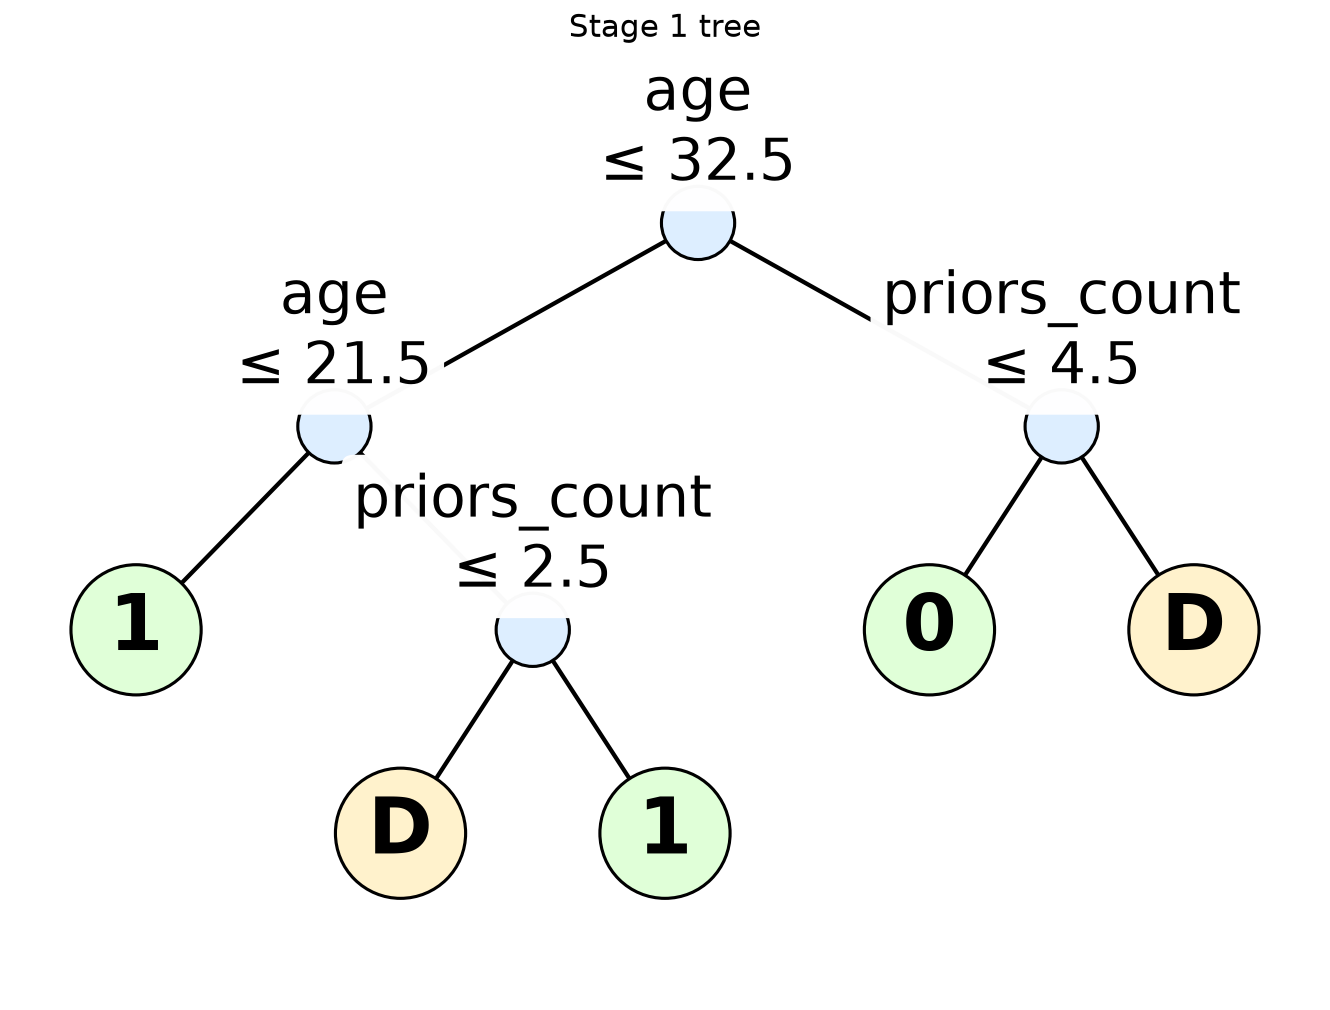

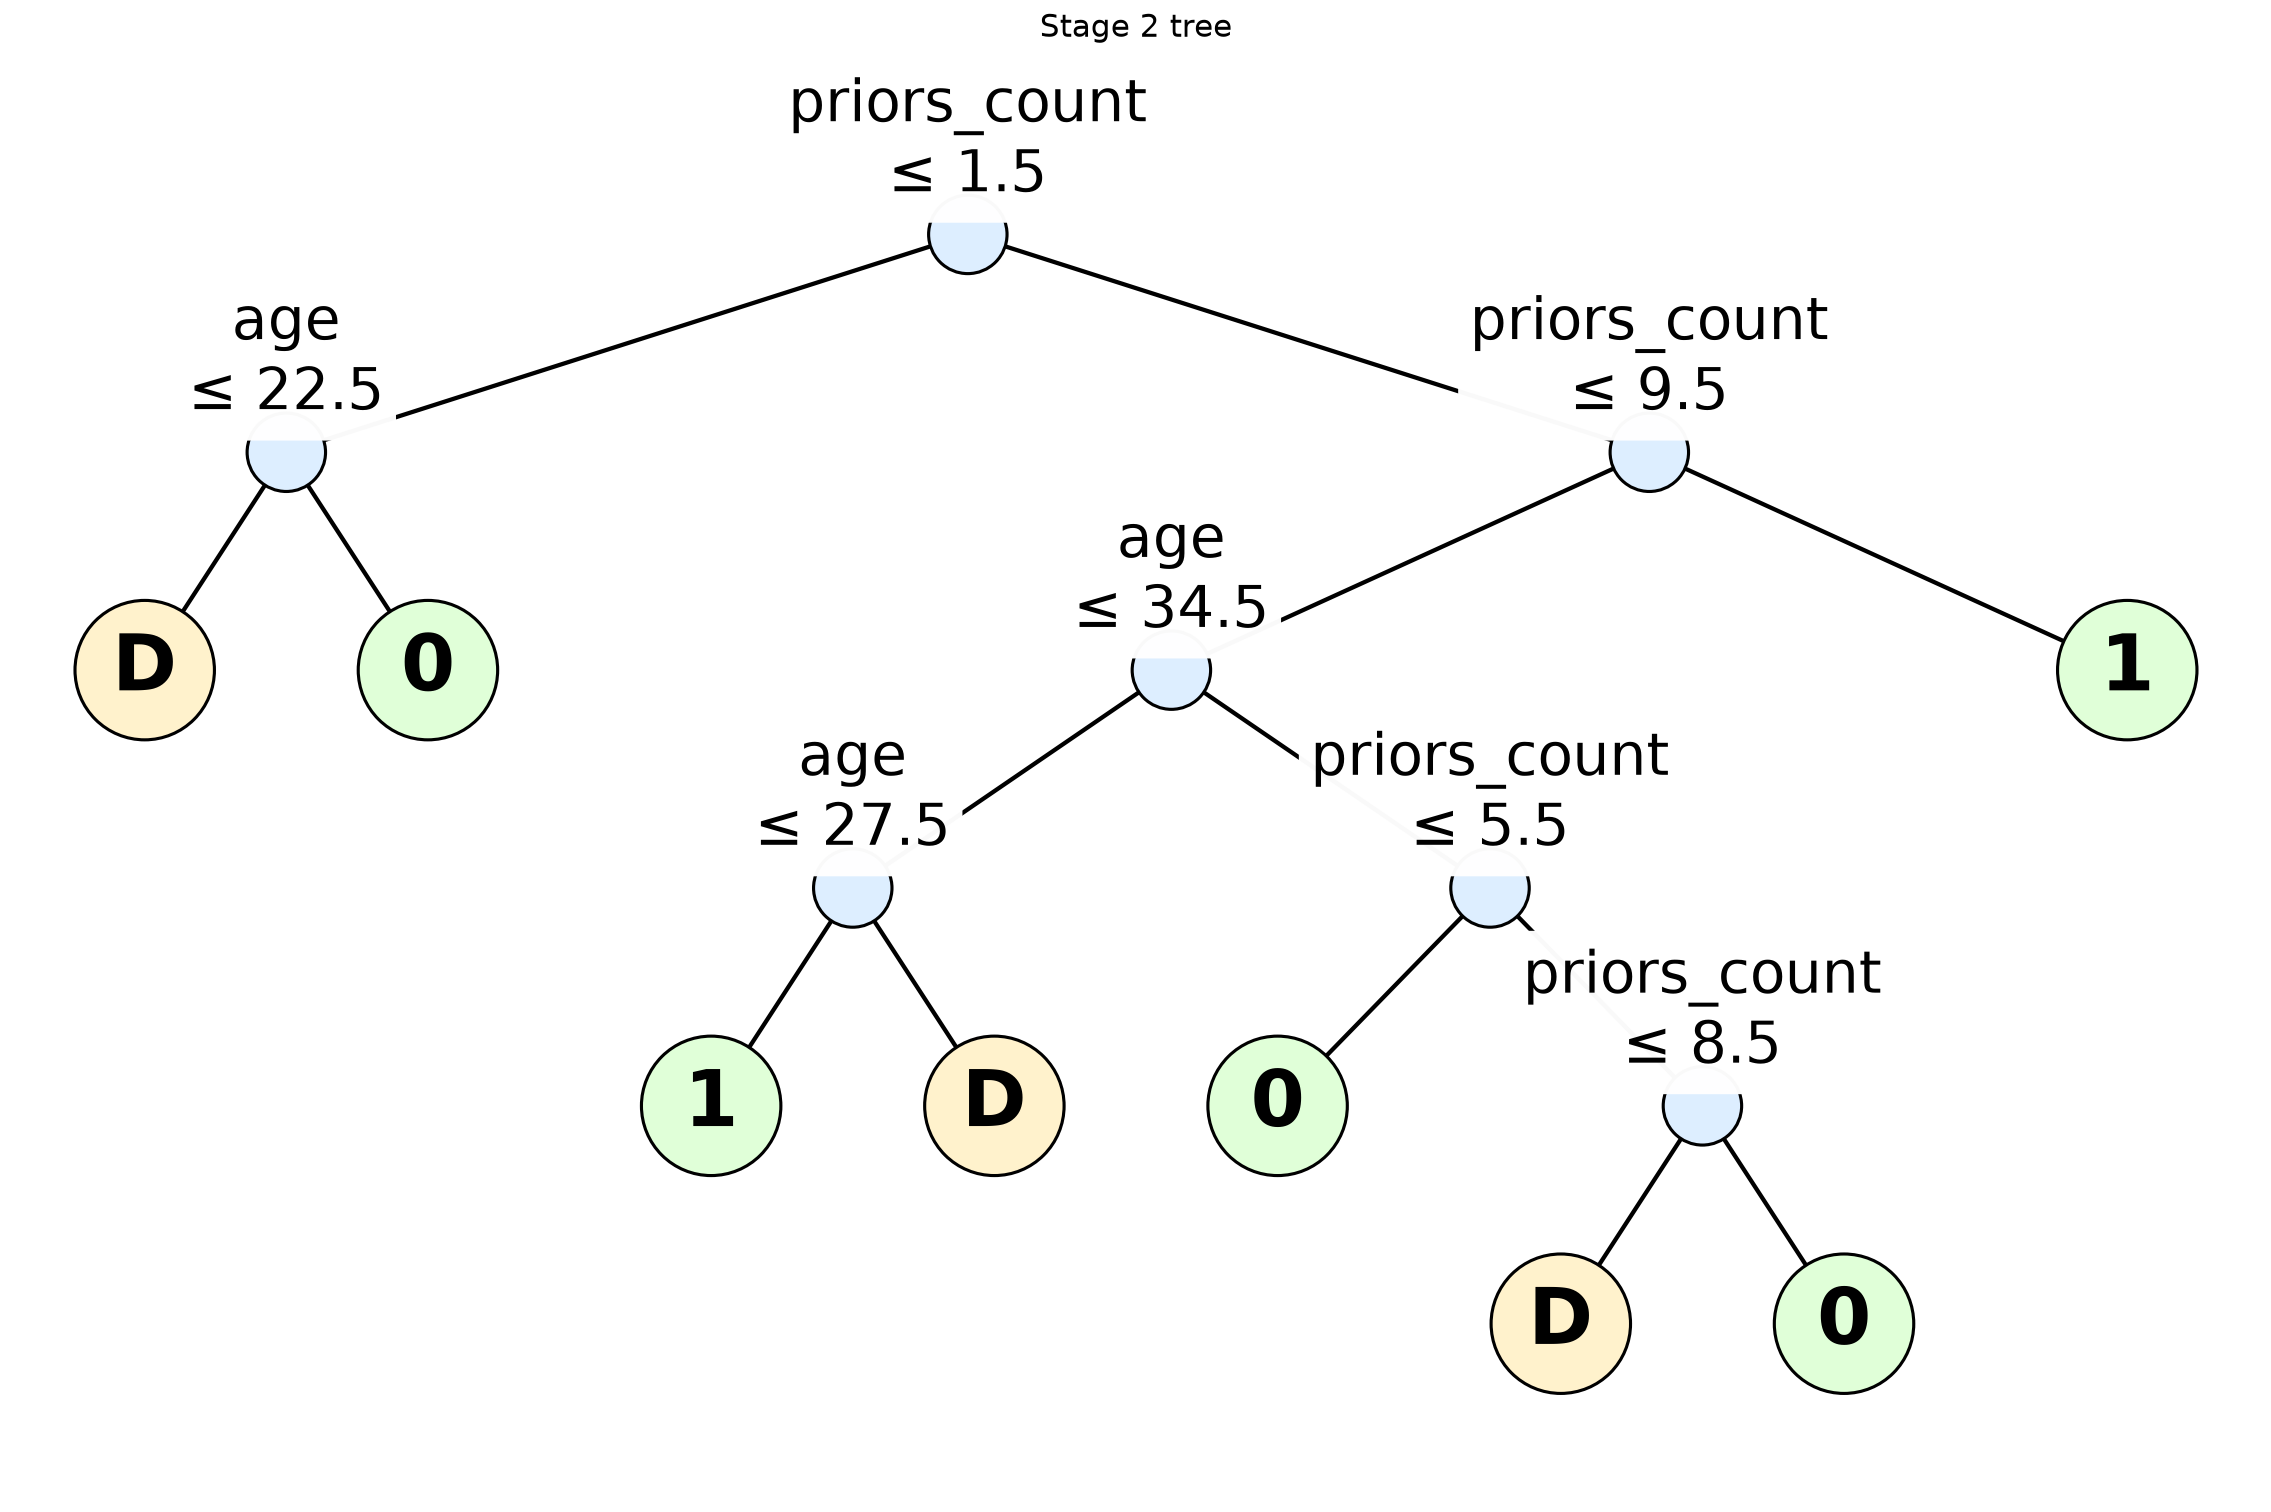

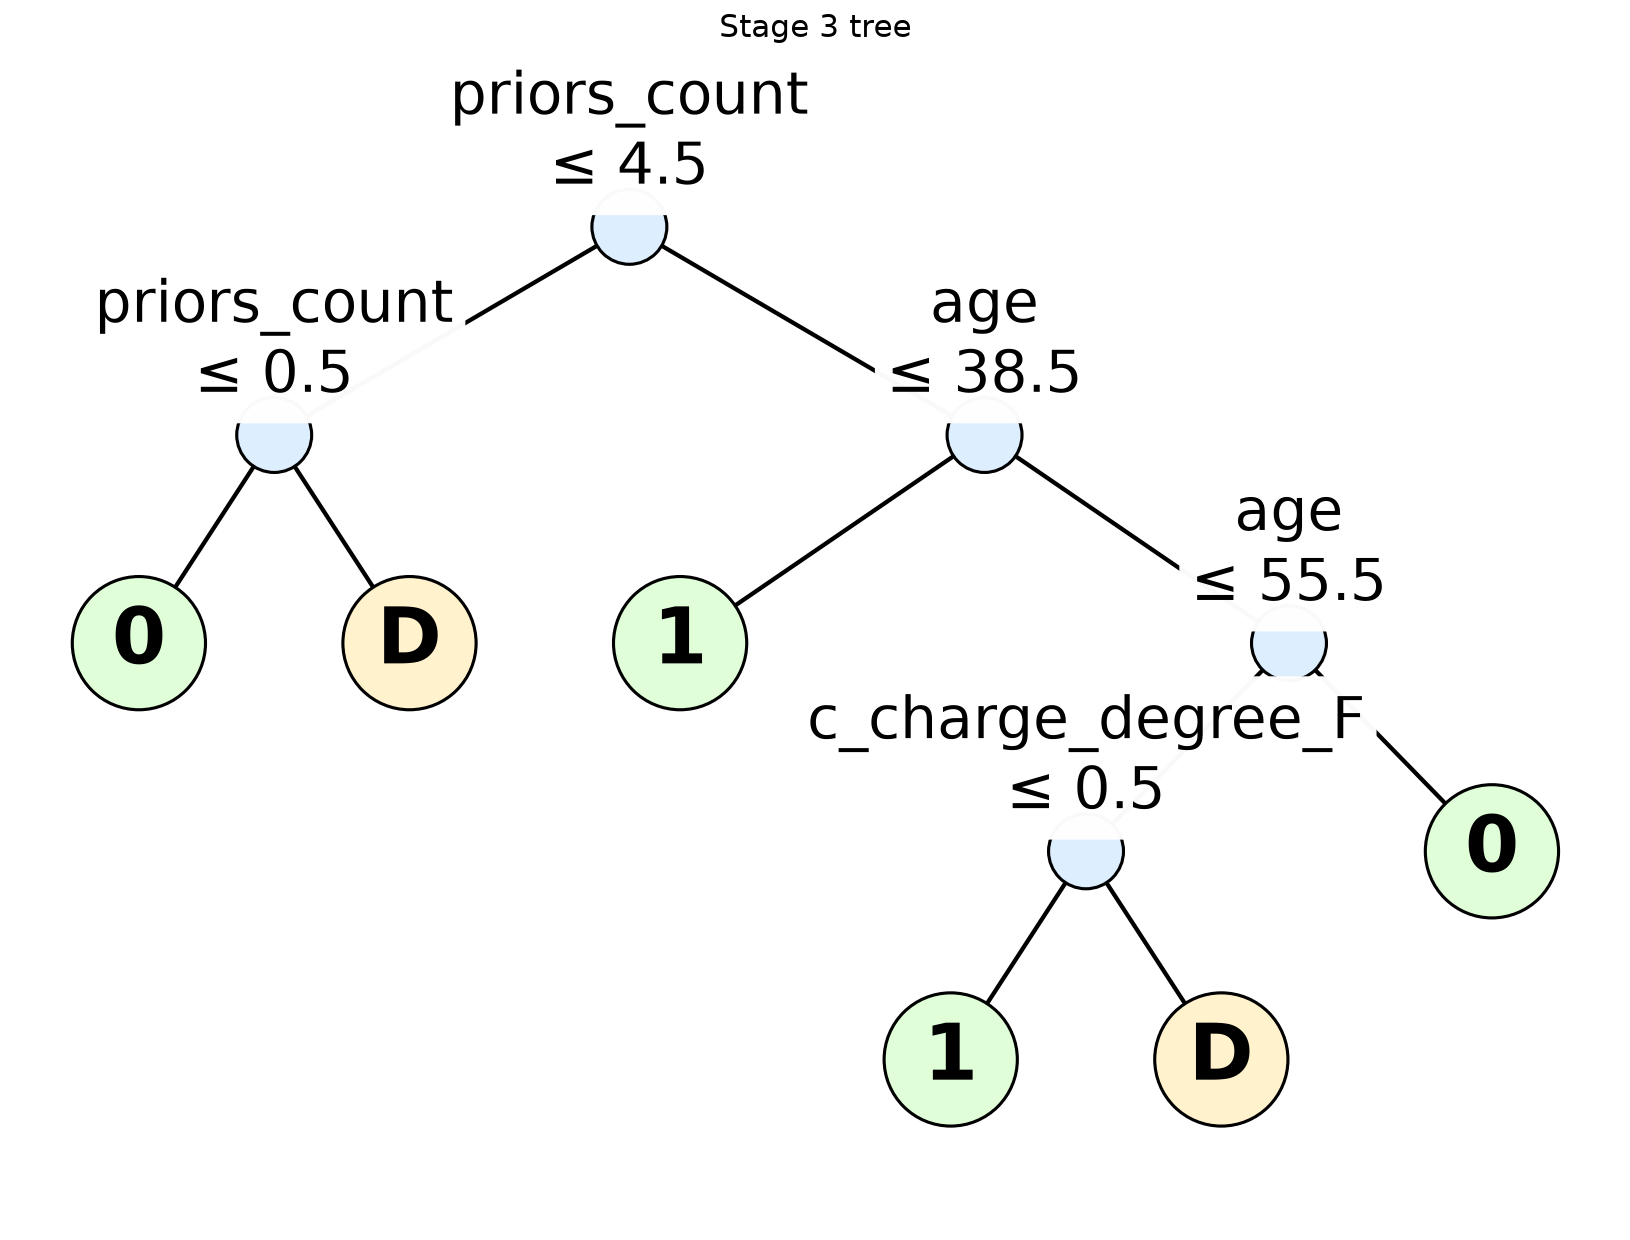

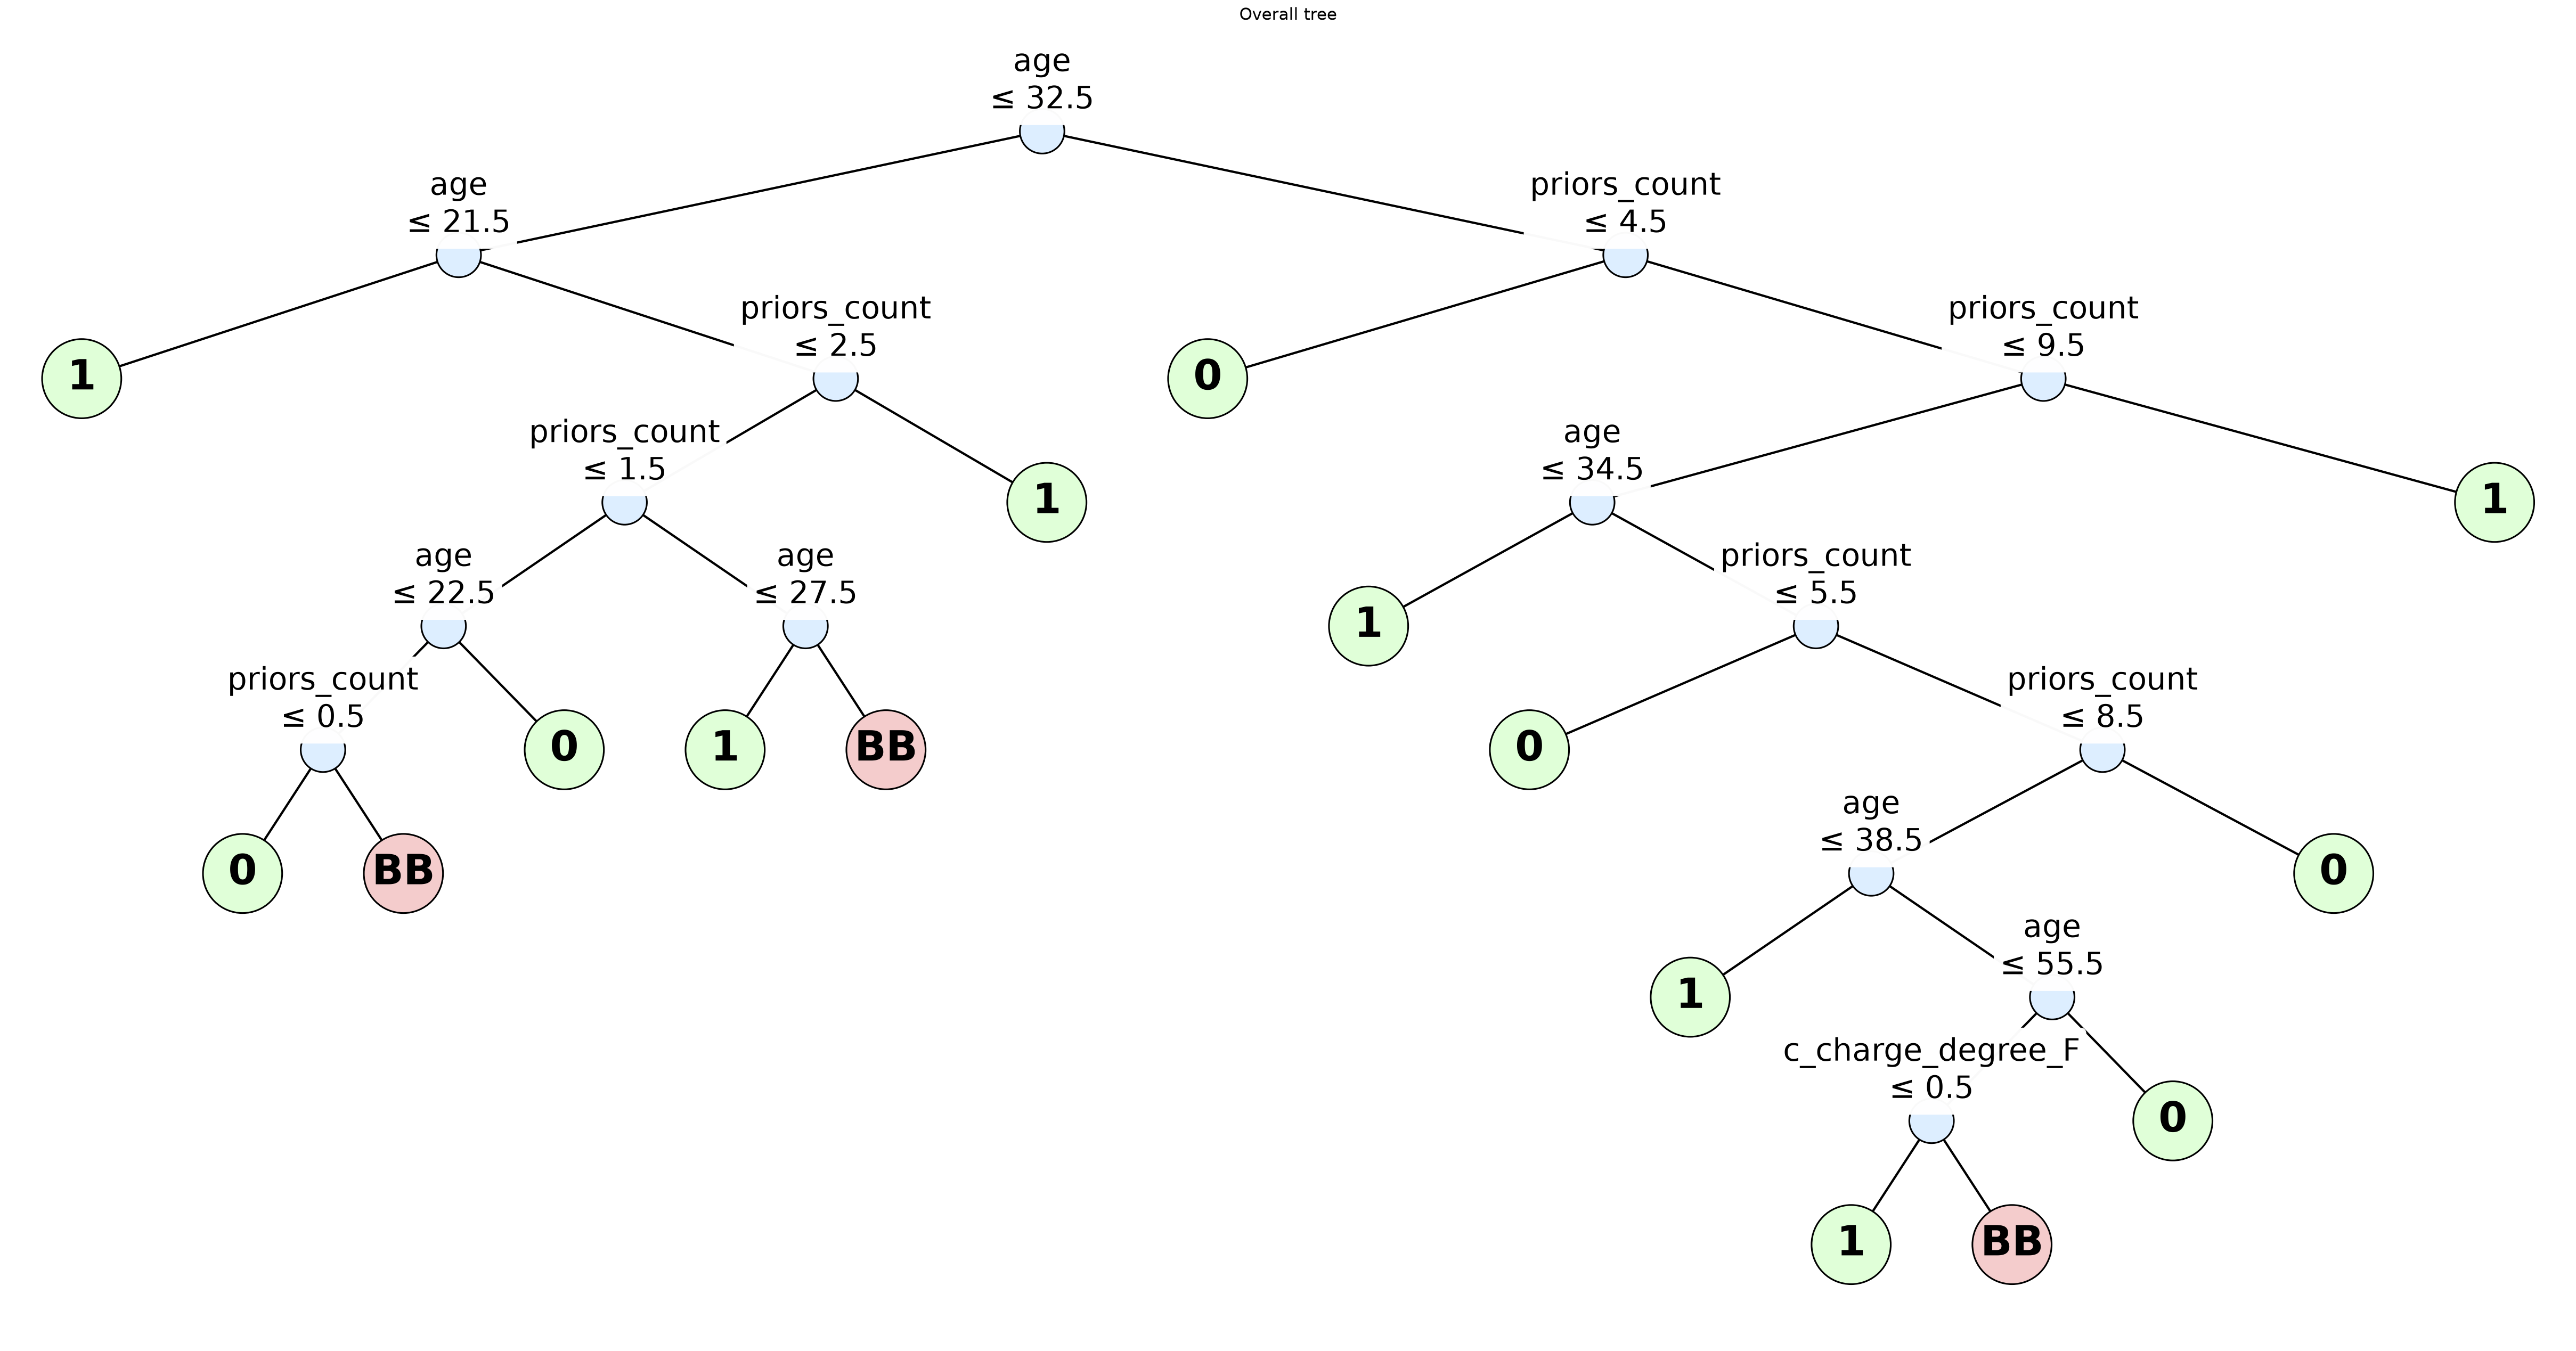

(<Figure size 6204.55x3937.5 with 1 Axes>,
 <Axes: title={'center': 'Overall tree'}>)

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score
from tabpfn import TabPFNClassifier
from tree_again import MDT

compas = pd.read_csv("https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv")
features = ["age", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count", "c_charge_degree"]
compas = compas[features + ["two_year_recid"]].dropna()
X = pd.get_dummies(compas[features], dtype=float)
y = compas["two_year_recid"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

tabpfn = TabPFNClassifier(random_state=42)
tabpfn.fit(X_train, y_train)
bb_train, bb_test = tabpfn.predict(X_train), tabpfn.predict(X_test)
mdt = MDT(
    lambda_leaf=0.0015,  # Leaf penalty; larger values favor smaller trees.
    eta_defer=0.01,  # Deferral penalty; smaller values encourage deferral.
    depth_budget=5,  # Maximum depth of each stage tree.
    max_stages=3,  # Maximum number of tree stages.
    c=0.5,  # Increase to focus later stages on deferred samples; decrease for a broader fit.
    gamma=0,  # Weight decay away from the deferred region; only tune if compute allows.
)
mdt.fit(X_train, y_train, bb_pred=bb_train)
hybrid_predictions = mdt.predict(X_test, bb_pred=bb_test)
_, deferred = mdt.predict_with_eventual_deferral(X_test, bb_pred=bb_test)
print(f"TabPFN test accuracy: {accuracy_score(y_test, bb_test):.4f}")
print(f"Hybrid test accuracy: {accuracy_score(y_test, hybrid_predictions):.4f}")
print(f"Test deferral rate: {deferred.mean():.4f}")

for i in range(len(mdt.stages_)):
    mdt.plot_stage_tree(i, compressed=True, dag_representation=True)
mdt.plot_single_tree(compress=True, title="Overall tree")


# Regression: Abalone + CLARITree + random forest

Random forest test RMSE: 2.1861
Random forest test R2: 0.5354
Hybrid test RMSE: 2.2200
Hybrid test R2: 0.5209
Test deferral rate: 0.5014

Stage 1 linear models (ring-count units):


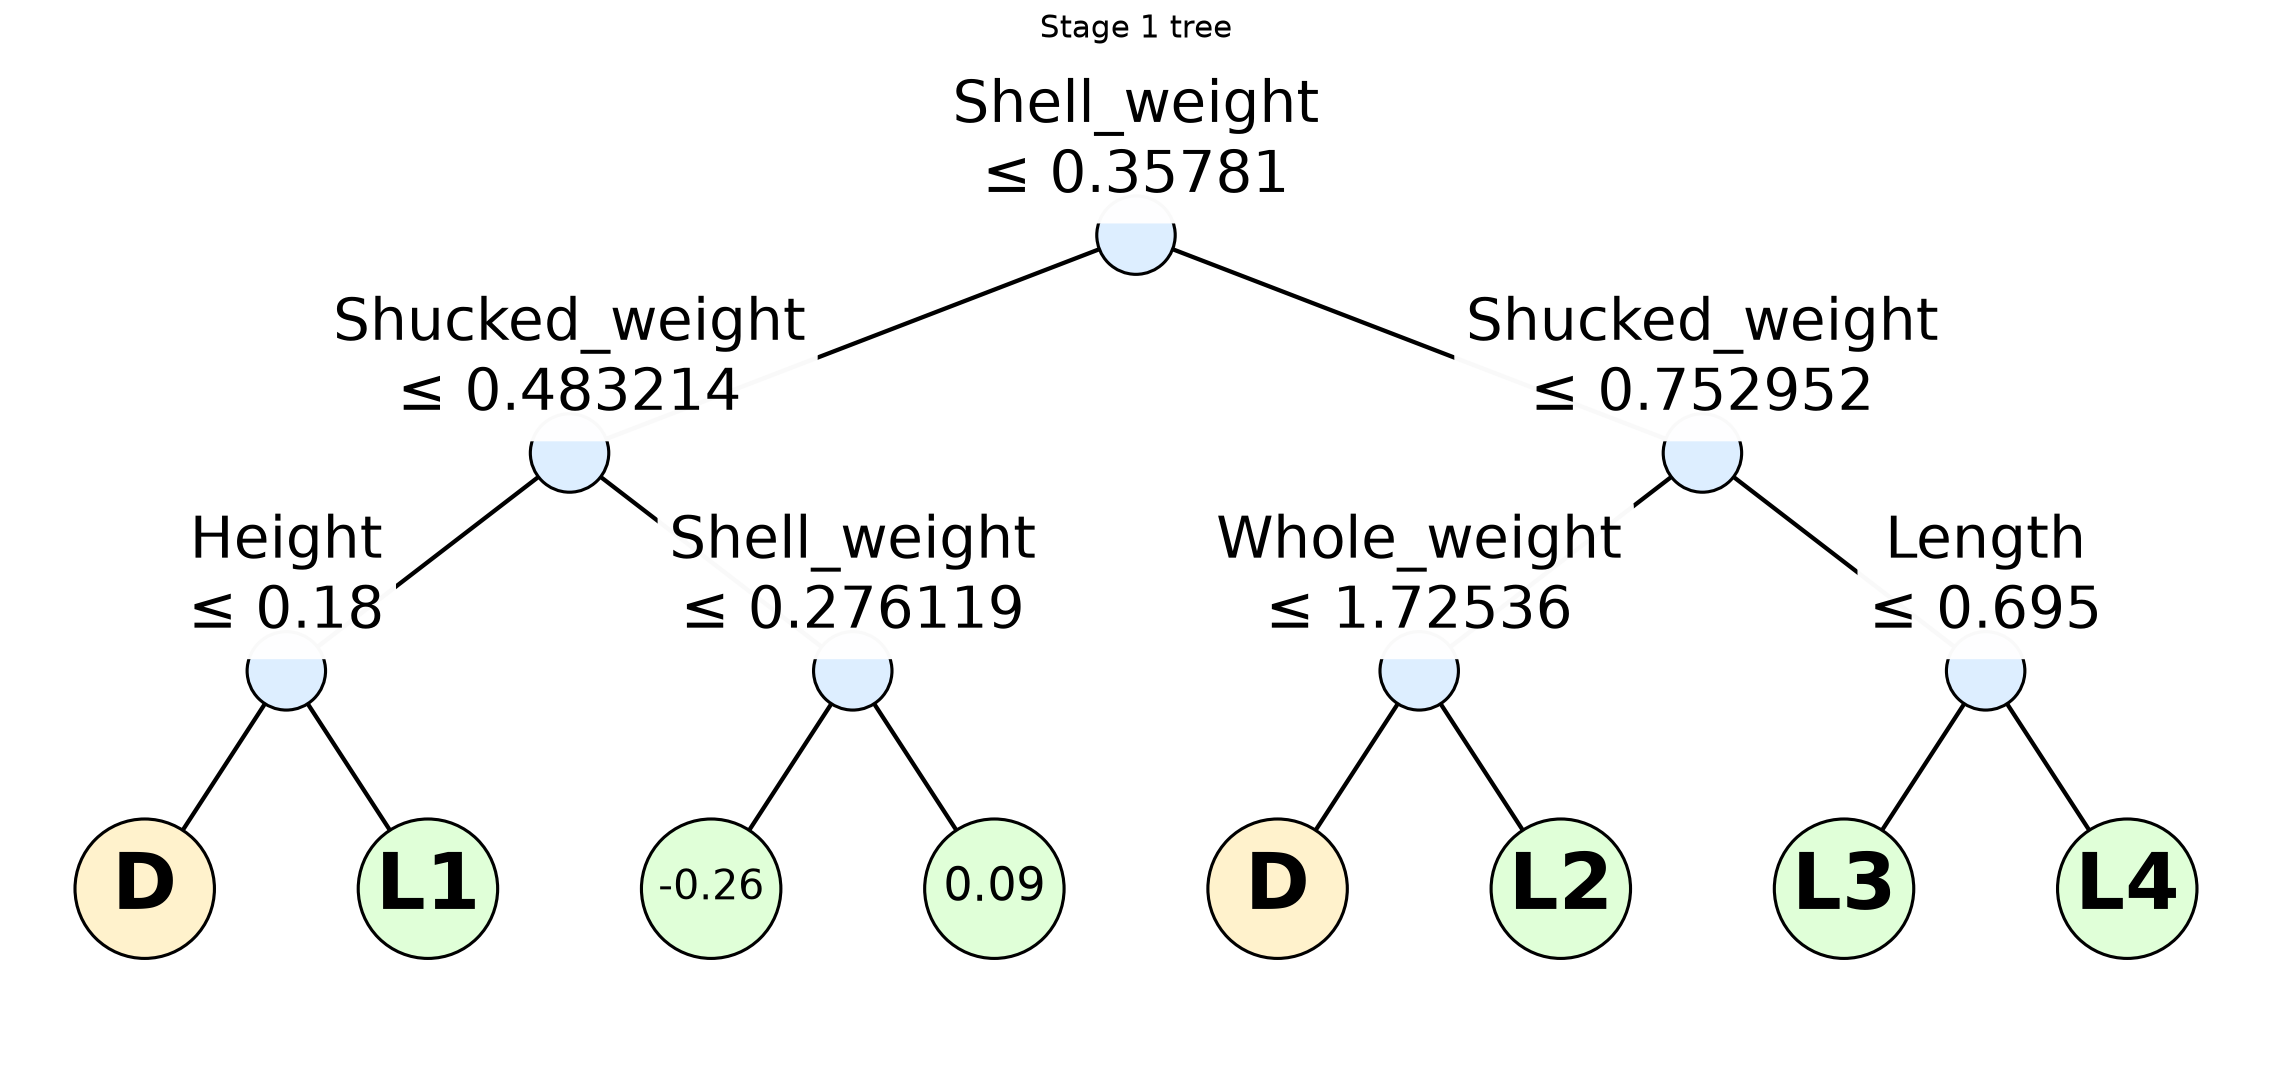

L1: Rings = 25.9339 -14.3898*Length -19.4655*Diameter -5.8559*Height +3.0866*Whole_weight -6.2524*Shucked_weight +13.4099*Viscera_weight +7.3222*Shell_weight
L2: Rings = 23.1872 -14.7781*Length +2.4445*Diameter -31.0730*Height +2.8601*Whole_weight +0.1573*Shucked_weight -7.9006*Viscera_weight +8.8136*Shell_weight
L3: Rings = -4.8946 +0.0182*Length +5.7856*Diameter +27.9395*Height +0.6500*Whole_weight -4.4745*Shucked_weight -1.5854*Viscera_weight +23.6614*Shell_weight
L4: Rings = 6.1155 +1.3288*Length -0.1666*Diameter -2.8095*Height +1.2721*Whole_weight -1.4365*Shucked_weight -2.5947*Viscera_weight +9.1429*Shell_weight

Stage 2 linear models (ring-count units):


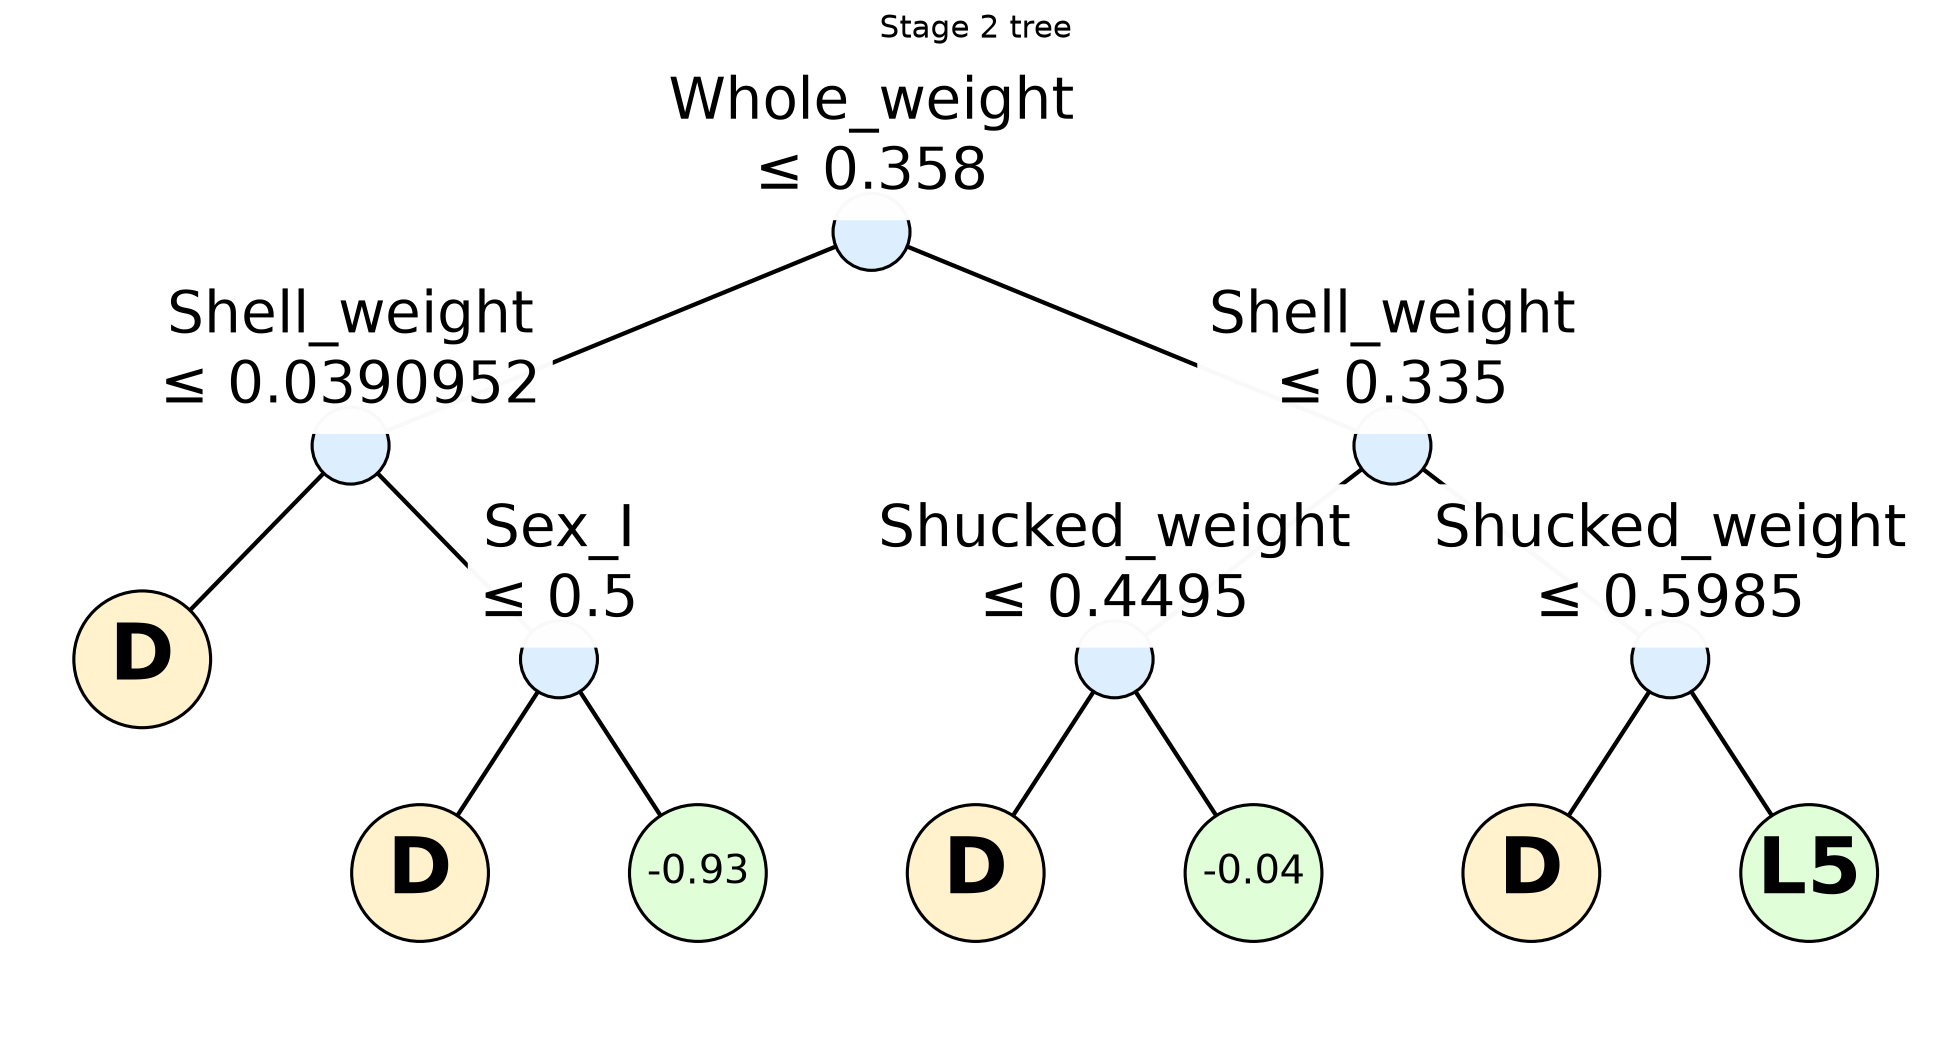

L5: Rings = 11.0130 -12.5898*Length +9.3470*Diameter +0.6113*Height +3.5631*Whole_weight -8.0197*Shucked_weight -3.5160*Viscera_weight +11.8366*Shell_weight

Stage 3 linear models (ring-count units):


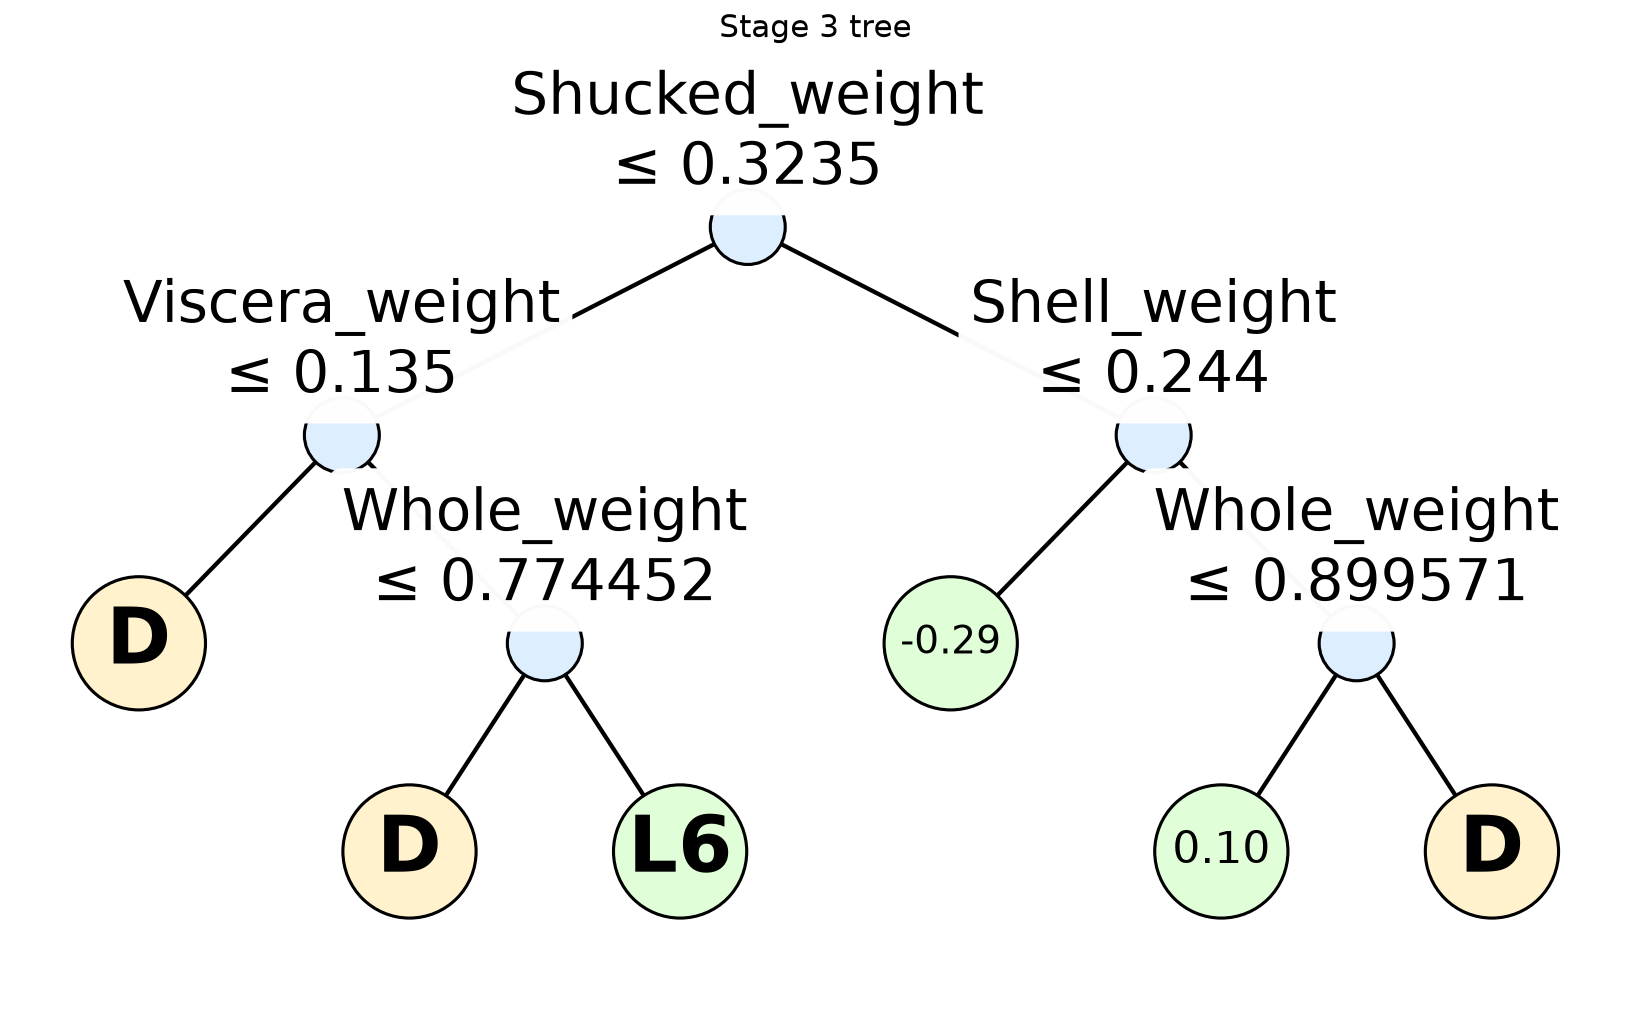

L6: Rings = 30.5435 -14.5476*Length -31.0516*Diameter +13.0410*Height +2.3407*Whole_weight -6.9178*Shucked_weight -13.4283*Viscera_weight +17.3450*Shell_weight




(<Figure size 13236.4x3937.5 with 1 Axes>,
 <Axes: title={'center': 'Overall tree'}>)

In [2]:
abalone = pd.read_csv("https://archive.ics.uci.edu/ml/machine-learning-databases/abalone/abalone.data", header=None,
                      names=["Sex", "Length", "Diameter", "Height", "Whole_weight", "Shucked_weight", "Viscera_weight", "Shell_weight", "Rings"])
X = pd.get_dummies(abalone.drop(columns="Rings"), dtype=float)
y = abalone["Rings"].astype(float)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
target_mean, target_scale = y_train.mean(), y_train.std(ddof=0)
rf_params = {
    "n_estimators": 100,
    "max_depth": 5,
    "min_samples_leaf": 4,
    "n_jobs": 2,
    "random_state": 42,
}
rf = RandomForestRegressor(**rf_params)
rf.fit(X_train, (y_train - target_mean) / target_scale)
rf_predictions = rf.predict(X_test) * target_scale + target_mean

reg_mdt = MDT(
    # "regression" uses constant prediction leaves without CLARITree.
    # "linear_regression" uses CLARITree and allows linear leaves for extra accuracy.
    task="linear_regression",
    black_box_type="random_forest",  # Final fallback model.
    black_box_params=rf_params,  # Forest settings used when fitting the fallback.
    retrain_black_box=True,  # Refit the fallback using stage weights.
    lambda_leaf=0.0015,  # Leaf penalty; larger values favor smaller trees.
    eta_defer=0.06,  # Deferral penalty; smaller values encourage deferral.
    depth_budget=3,  # Maximum depth of each stage tree.
    max_stages=3,  # Maximum number of tree stages.
    gamma=0,  # Weight decay away from the deferred region; only tune if compute allows.
    claritree_params={"rho": 0.05},  # Extra penalty for choosing a linear leaf.
)
reg_mdt.fit(X_train, (y_train - target_mean) / target_scale)
hybrid_predictions = reg_mdt.predict(X_test) * target_scale + target_mean
_, deferred = reg_mdt.predict_with_eventual_deferral(X_test)
print(f"Random forest test RMSE: {np.sqrt(mean_squared_error(y_test, rf_predictions)):.4f}")
print(f"Random forest test R2: {r2_score(y_test, rf_predictions):.4f}")
print(f"Hybrid test RMSE: {np.sqrt(mean_squared_error(y_test, hybrid_predictions)):.4f}")
print(f"Hybrid test R2: {r2_score(y_test, hybrid_predictions):.4f}")
print(f"Test deferral rate: {deferred.mean():.4f}")

linear_id = 1
for stage_index, stage in enumerate(reg_mdt.stages_):
    print(f"\nStage {stage_index + 1} linear models (ring-count units):")
    reg_mdt.plot_stage_tree(stage_index, compressed=True, dag_representation=True)
    for leaf in stage.export_leaf_paths():
        if leaf["leaf_type"] == "LINEAR":
            beta = np.asarray(leaf["coefficients"]) * target_scale
            terms = " ".join(f"{weight:+.4f}*{X_train.columns[int(index) - 1]}"
                             for index, weight in zip(leaf["continuous_idx"], beta[1:]))
            print(f"L{linear_id}: Rings = {target_mean + beta[0]:.4f} {terms}")
            linear_id += 1

reg_mdt.plot_single_tree(compress=True, title="Overall tree")
